# Privacy-Aware Android App Permission Management
## Borda-Garrett Ranking + Association Rule Mining + Reinforcement Learning

**Category focus:** `Social & Communication`

> **v2 changelog (accuracy-focused revision):** the malicious-risk classifier now (1) uses the
> full non-constant permission set instead of only the RL's TOP_K permissions, plus two new
> engineered metadata features, and (2) is selected and hyperparameter-tuned with stratified
> k-fold cross-validation, with SMOTE folded *inside* each CV fold (via an `imblearn` pipeline)
> to avoid synthetic-sample leakage across folds. The RL reward-coefficient grid was widened so
> the agent is not structurally nudged toward "allow everything". A bootstrap confidence interval
> was added to the final test accuracy so a single-split number isn't over-interpreted on a
> ~225-app test set. Everything else -- the train/val/test discipline, the no-label-leakage
> guarantees, the honest reporting of weak/absent signal -- is unchanged from v1.

### Objective

Build a Reinforcement Learning (RL) agent that learns to **ALLOW** or **DENY** individual Android
permission requests for apps in the *Social & Communication* category, balancing four signals:

1. **App utility** — how commonly/usefully a permission is used by benign apps in this category
2. **Individual permission privacy risk** — precomputed Borda + Garrett combined importance weight
3. **Permission-interaction risk** — statistically mined 2-permission association rules (trained only on the training split)
4. **Malicious-app probability** — a supervised classifier trained only on the training split

### Methodology pipeline

```
Android Dataset
        |
Category-specific Permission Matrix   (Social & Communication)
        |
Feature Engineering                   (PermissionCount, DangerousToSafeRatio)
        |
Borda + Garrett Combined Weights      (precomputed externally, loaded not recomputed)
        |
Top Category-specific Permissions     (TOP_K, configurable -- RL action space only)
        |
Association Rule Mining               (TRAIN split only)
        |
Statistically Supported Permission Interactions
        |
Malicious Risk Model                  (TRAIN split only, cross-validated model + hyperparameter selection)
        |
Evidence-based Utility + Privacy Risk (TRAIN split only)
        |
RL Environment  ->  Q-Learning  ->  Allow / Deny Policy
        |
Privacy Score + Utility
        |
Final Test Evaluation (held-out TEST split, touched only once) + Bootstrap CI
```

**Design guarantees enforced throughout this notebook:**
- The test set is never used for weight learning, rule mining, utility/risk estimation, RL training,
  hyperparameter selection, or threshold selection -- only for the final reported numbers.
- The RL environment never receives the true `Class` label as part of its reward signal.
- The reward function is constructed so that `Deny` is never trivially better than `Allow`
  (no "deny everything" collapse) -- see Sections 16/17.
- Borda/Garrett weights are **loaded from `combined_weights_social_communication.csv`**, never recomputed.
- The malicious-risk classifier's feature set is independent of the RL's TOP_K action space --
  broadening it does not change what the RL agent can Allow/Deny.


## 2. Imports and Configuration

In [1]:
import warnings
warnings.filterwarnings("default")  # show warnings, never hide them

import os
import json
import random
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)


In [2]:
# ---------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# ---------------------------------------------------------------
# Project configuration (all important parameters live here)
# ---------------------------------------------------------------
CATEGORY = "Social & Communication"
# The raw dataset's `Category` column does not contain a literal
# "Social & Communication" value. It contains the finer-grained
# categories "Communication" and "Social" separately. We map both
# of these raw categories onto the broad project category below.
# This mapping is applied explicitly (Section 6) and is NOT a
# silent fabrication of data -- it is documented here and printed.
CATEGORY_RAW_VALUES = ["Communication", "Social"]

DATA_PATH = "Android_Permission.csv"
WEIGHTS_PATH = "combined_weights_social_communication.csv"
OUTPUT_DIR = "results_RL_Social_and_Communication"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Top-K category-specific permissions used for the RL state/action space.
# Configurable per Step 5 of the specification. NOTE: this only controls what the RL
# agent can Allow/Deny -- the malicious-risk classifier (Section 12) uses a separate,
# broader feature set (CLF_PERMISSION_FEATURES), decoupled from this value.
TOP_K = 12

# Extra real per-app metadata features added to the malicious-risk classifier ONLY
# (never part of the RL action space -- you cannot "Allow/Deny" a rating).
# Section 7b appends two more engineered features (PermissionCount, DangerousToSafeRatio)
# to this list once they are computed.
METADATA_FEATURES = ["Rating", "Number of ratings", "Price",
                     "Dangerous permissions count", "Safe permissions count"]

# SMOTE oversampling target ratio for the minority class in TRAINING data only.
# 1.0 = fully balance minority to match majority count.
SMOTE_TARGET_RATIO = 1.0

# Number of folds for cross-validated classifier model/hyperparameter selection (Section 12).
N_CV_FOLDS = 5

# Association rule mining thresholds (Step 6). These are NOT relaxed
# just to manufacture more rules -- if few/no rules survive, that is
# reported honestly rather than hidden.
MIN_SUPPORT = 0.04
MIN_CONFIDENCE = 0.60
MIN_LIFT = 1.02

# Reward coefficient candidates evaluated on the VALIDATION set (Step 12/16).
# Widened from v1 to include settings where BETA/GAMMA (privacy penalty) are large
# relative to ALPHA (utility reward) -- v1's candidates were all utility-dominant, which is
# part of why the learned policy converged to an ~allow-everything policy indistinguishable
# from the AllowAll baseline. Including higher-penalty candidates lets the validation-based
# selection actually choose a more risk-sensitive policy if one performs better.
COEF_CANDIDATES = [
    (0.60, 0.25, 0.15),
    (0.70, 0.20, 0.10),
    (0.50, 0.30, 0.20),
    (0.45, 0.40, 0.15),
    (0.35, 0.50, 0.15),
    (0.30, 0.55, 0.15),
]

# Q-learning hyperparameters (Step 15)
QL_ALPHA = 0.1           # learning rate
QL_GAMMA = 0.9            # discount factor
QL_EPISODES = 5000
QL_EPS_START = 1.0
QL_EPS_MIN = 0.05
QL_EPS_DECAY = 0.999

# Predefined privacy-score thresholds (Step 19). These are declared as
# FIXED / predefined thresholds, not learned from data.
PRIVACY_LOW_THRESHOLD = 0.33
PRIVACY_HIGH_THRESHOLD = 0.67

print("Configuration loaded.")
print("CATEGORY:", CATEGORY, "<- raw Category values:", CATEGORY_RAW_VALUES)
print("TOP_K:", TOP_K)
print("N_CV_FOLDS:", N_CV_FOLDS)
print("Association rule thresholds:", MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT)
print("Reward coefficient candidates:", COEF_CANDIDATES)


Configuration loaded.
CATEGORY: Social & Communication <- raw Category values: ['Communication', 'Social']
TOP_K: 12
N_CV_FOLDS: 5
Association rule thresholds: 0.04 0.6 1.02
Reward coefficient candidates: [(0.6, 0.25, 0.15), (0.7, 0.2, 0.1), (0.5, 0.3, 0.2), (0.45, 0.4, 0.15), (0.35, 0.5, 0.15), (0.3, 0.55, 0.15)]


## 3. Load Dataset

Loads the raw Android permission dataset and performs basic structural checks
(shape, missing values, class balance, category distribution).

In [3]:
df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset shape:", df.shape)
print()
print("Missing values per column (only columns with >0 missing shown):")
missing_counts = df.isna().sum()
print(missing_counts[missing_counts > 0])
print()
print("Class distribution (0 = Benign, 1 = Malicious):")
print(df["Class"].value_counts())
print()
print("Category distribution (top 15):")
print(df["Category"].value_counts().head(15))

Dataset shape: (29999, 184)

Missing values per column (only columns with >0 missing shown):
App                              1
Description                      3
Related apps                   755
Dangerous permissions count    204
dtype: int64

Class distribution (0 = Benign, 1 = Malicious):
Class
1    20000
0     9999
Name: count, dtype: int64

Category distribution (top 15):
Category
Entertainment        2827
Travel & Local       2154
Arcade & Action      1959
Books & Reference    1959
Brain & Puzzle       1873
Casual               1678
Personalization      1527
Lifestyle            1435
Tools                1329
Education            1305
Communication        1103
Finance              1045
Health & Fitness     1038
Business              945
Cards & Casino        881
Name: count, dtype: int64


## 4. Load Combined Borda-Garrett Weights (Precomputed Project Input)

`combined_weights_social_communication.csv` contains the **already-computed** Borda + Garrett
combined importance weight for each permission in this category. These weights were derived
externally (outside this notebook) from the full dataset methodology described in the project,
and are treated here strictly as a **precomputed input** -- they are loaded, validated, and used,
but **never recomputed**.

In [4]:
weights_df = pd.read_csv(WEIGHTS_PATH)
print("Raw combined weights:")
print(weights_df)

weight_sum = weights_df["CombinedWeight"].sum()
print("\nSum of CombinedWeight:", weight_sum)

if not np.isclose(weight_sum, 1.0, atol=1e-2):
    print("Sum is not ~1.0 -> normalizing.")
    weights_df["CombinedWeight"] = weights_df["CombinedWeight"] / weight_sum
else:
    print("Sum is already ~1.0 -> no normalization needed.")

weights_df = weights_df.sort_values("CombinedWeight", ascending=False).reset_index(drop=True)
weights_df["Rank"] = weights_df.index + 1

weight_map = dict(zip(weights_df["Permission"], weights_df["CombinedWeight"]))

print("\nCombined Borda + Garrett weights (sorted descending):")
weights_df

Raw combined weights:
          Permission  CombinedWeight
0           Location        0.105413
1           Internet        0.105413
2            Storage        0.104215
3             Camera        0.100210
4         PhoneState        0.100058
5         Microphone        0.097402
6          Bluetooth        0.088193
7           Calendar        0.084035
8           Contacts        0.080030
9                SMS        0.080030
10          CallLogs        0.027501
11  ReadPhoneNumbers        0.027501

Sum of CombinedWeight: 0.9999999999999996
Sum is already ~1.0 -> no normalization needed.

Combined Borda + Garrett weights (sorted descending):


,Permission,CombinedWeight,Rank
0,Location,0.105413,1
1,Internet,0.105413,2
2,Storage,0.104215,3
3,Camera,0.100210,4
4,PhoneState,0.100058,5
5,Microphone,0.097402,6
6,Bluetooth,0.088193,7
7,Calendar,0.084035,8
8,Contacts,0.080030,9
9,SMS,0.080030,10


## 5. Data Validation

Validates that every raw Android permission column referenced by `PERMISSION_COLUMN_MAP`
actually exists in the dataset. Missing columns are **reported explicitly**, never silently
fabricated or filled with defaults.

In [5]:
PERMISSION_COLUMN_MAP = {
    "Camera": [
        "Hardware controls : take pictures and videos (D)"
    ],
    "Location": [
        "Your location : coarse (network-based) location (D)",
        "Your location : fine (GPS) location (D)",
        "Default : coarse (network-based) location (S)"
    ],
    "Contacts": [
        "Your personal information : read contact data (D)",
        "Your personal information : write contact data (D)",
        "Default : write contact data (S)",
        "Your accounts : contacts data in Google accounts (D)"
    ],
    "Microphone": [
        "Hardware controls : record audio (D)"
    ],
    "Storage": [
        "Storage : modify/delete USB storage contents modify/delete SD card contents (D)",
        "Default : modify/delete USB storage contents modify/delete SD card contents (S)"
    ],
    "SMS": [
        "Services that cost you money : send SMS messages (D)",
        "Your messages : edit SMS or MMS (D)",
        "Your messages : read SMS or MMS (D)",
        "Your messages : receive SMS (D)",
        "Your messages : receive MMS (D)",
        "Your messages : send SMS-received broadcast (S)"
    ],
    "CallLogs": [],
    "Bluetooth": [
        "Network communication : create Bluetooth connections (D)",
        "System tools : bluetooth administration (D)"
    ],
    "Calendar": [
        "Your personal information : add or modify calendar events and send email to guests (D)",
        "Your personal information : read calendar events (D)"
    ],
    "PhoneState": [
        "Default : read phone state and identity (S)",
        "Phone calls : read phone state and identity (D)"
    ],
    "Internet": [
        "Default : full Internet access (S)",
        "Network communication : full Internet access (D)"
    ],
    "ReadPhoneNumbers": []
}

PERMISSION_NAMES = list(PERMISSION_COLUMN_MAP.keys())

missing_report = {}
for perm, cols in PERMISSION_COLUMN_MAP.items():
    missing = [c for c in cols if c not in df.columns]
    if missing:
        missing_report[perm] = missing

if missing_report:
    print("WARNING -- missing raw columns detected (these are NOT silently fabricated):")
    for k, v in missing_report.items():
        print(f"   {k}: {v}")
else:
    print("All mapped raw permission columns that were expected to exist are present.")

empty_maps = [p for p, c in PERMISSION_COLUMN_MAP.items() if len(c) == 0]
print()
print("Permissions with NO raw column mapping available in this dataset")
print("(these will be constant 0 for every app -- reported honestly, not fabricated):")
print(empty_maps)

All mapped raw permission columns that were expected to exist are present.

Permissions with NO raw column mapping available in this dataset
(these will be constant 0 for every app -- reported honestly, not fabricated):
['CallLogs', 'ReadPhoneNumbers']


## 6. Category Filtering

The raw dataset has no `BroadCategory` column. We construct it by mapping the raw
`Category` values `"Communication"` and `"Social"` onto the broad project category
`"Social & Communication"`. This mapping is explicit and printed for verification.

In [6]:
if "BroadCategory" not in df.columns:
    def map_broad_category(cat):
        return "Social & Communication" if cat in CATEGORY_RAW_VALUES else "Other"

    broad_category = df["Category"].apply(map_broad_category)
    df = df.assign(BroadCategory=broad_category)
    print(f"Created BroadCategory column. Raw values mapped into '{CATEGORY}': {CATEGORY_RAW_VALUES}")

print(df["BroadCategory"].value_counts())

cat_df = df[df["BroadCategory"] == CATEGORY].copy()
print(f"\nApps in category '{CATEGORY}':", len(cat_df))
print("Benign  (Class=0):", (cat_df['Class'] == 0).sum())
print("Malicious (Class=1):", (cat_df['Class'] == 1).sum())

Created BroadCategory column. Raw values mapped into 'Social & Communication': ['Communication', 'Social']
BroadCategory
Other                     28497
Social & Communication     1502
Name: count, dtype: int64

Apps in category 'Social & Communication': 1502
Benign  (Class=0): 645
Malicious (Class=1): 857


C:\Users\Dhruvi\AppData\Local\Temp\ipykernel_9896\2814472726.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.assign(BroadCategory=broad_category)


## 7. Permission Matrix

Builds the 12 permission-level binary features. For permissions mapped to multiple raw
columns, `permission = 1` if **any** mapped raw column is 1. Raw Android permission columns
themselves are **not** included in the RL state -- only the aggregated permission-level
columns are used downstream.

In [7]:
def build_permission_matrix(source_df, colmap):
    out = pd.DataFrame(index=source_df.index)
    for perm, cols in colmap.items():
        present_cols = [c for c in cols if c in source_df.columns]
        if len(present_cols) == 0:
            out[perm] = 0
        else:
            out[perm] = (source_df[present_cols].fillna(0).astype(float).sum(axis=1) > 0).astype(int)
    return out

perm_feats = build_permission_matrix(cat_df, PERMISSION_COLUMN_MAP)

permission_matrix = pd.DataFrame({
    "App": cat_df["App"].values,
    "Category": cat_df["Category"].values,
})
for p in PERMISSION_NAMES:
    permission_matrix[p] = perm_feats[p].values

# Real per-app metadata, added for the malicious-risk classifier (Section 12).
for m in METADATA_FEATURES:
    permission_matrix[m] = pd.to_numeric(cat_df[m], errors="coerce").fillna(0).values

permission_matrix["LabelEncoded"] = cat_df["Class"].values

print("permission_matrix shape:", permission_matrix.shape)
print()
print("Class distribution within category:")
print(permission_matrix["LabelEncoded"].value_counts())
print()
print("Permission counts (number of apps requesting each permission):")
print(permission_matrix[PERMISSION_NAMES].sum())
print()
print("Permission support (fraction of apps requesting each permission):")
print(permission_matrix[PERMISSION_NAMES].mean().round(4))

permission_matrix.head()

permission_matrix shape: (1502, 20)

Class distribution within category:
LabelEncoded
1    857
0    645
Name: count, dtype: int64

Permission counts (number of apps requesting each permission):
Camera               223
Location             531
Contacts             652
Microphone           288
Storage              798
SMS                  381
CallLogs               0
Bluetooth            142
Calendar              33
PhoneState           797
Internet            1291
ReadPhoneNumbers       0
dtype: int64

Permission support (fraction of apps requesting each permission):
Camera              0.1485
Location            0.3535
Contacts            0.4341
Microphone          0.1917
Storage             0.5313
SMS                 0.2537
CallLogs            0.0000
Bluetooth           0.0945
Calendar            0.0220
PhoneState          0.5306
Internet            0.8595
ReadPhoneNumbers    0.0000
dtype: float64


,App,Category,Camera,Location,Contacts,Microphone,Storage,SMS,CallLogs,Bluetooth,Calendar,PhoneState,Internet,ReadPhoneNumbers,Rating,Number of ratings,Price,Dangerous permissions count,Safe permissions count,LabelEncoded
0,"Chat, Games, Fun",Social,0,1,1,0,1,0,0,0,0,1,1,0,4.1,22987,0.0,7.0,2,1
1,Caller Intelligence App,Communication,0,0,1,0,0,1,0,0,0,1,1,0,3.3,21,0.0,9.0,1,1
2,RocketDial Language Pack,Communication,0,0,0,0,0,0,0,0,0,0,0,0,4.4,197,0.0,0.0,0,1
3,LED Dance!,Communication,0,1,0,0,0,0,0,0,0,1,1,0,4.2,94,0.0,4.0,3,0
4,Bluetooth T.K,Communication,0,0,0,0,0,0,0,1,0,0,0,0,4.0,2,0.0,2.0,0,1


In [8]:
# ---------------------------------------------------------------
# Engineered metadata features (real, derived from existing columns -- nothing fabricated)
# ---------------------------------------------------------------
permission_matrix["PermissionCount"] = permission_matrix[PERMISSION_NAMES].sum(axis=1)

_dangerous = permission_matrix["Dangerous permissions count"].astype(float)
_safe = permission_matrix["Safe permissions count"].astype(float)
permission_matrix["DangerousToSafeRatio"] = (_dangerous / (_dangerous + _safe + 1e-6)).clip(0, 1)

ENGINEERED_METADATA_FEATURES = ["PermissionCount", "DangerousToSafeRatio"]
METADATA_FEATURES = METADATA_FEATURES + ENGINEERED_METADATA_FEATURES

print("Added engineered metadata features:", ENGINEERED_METADATA_FEATURES)
print("METADATA_FEATURES now:", METADATA_FEATURES)

# Computed here (not in Section 12) because the SMOTE step (Section 8b) and the RL environment
# (Section 15) both need to know the classifier's full permission feature set too, and both run
# before Section 12 in the notebook. Value never changes once permission_matrix is built.
CLF_PERMISSION_FEATURES = [p for p in PERMISSION_NAMES if permission_matrix[p].nunique() > 1]
print("\nCLF_PERMISSION_FEATURES (non-constant permissions, used by the classifier in Section 12):")
print(CLF_PERMISSION_FEATURES)

permission_matrix[["App", "PermissionCount", "DangerousToSafeRatio"]].describe()


Added engineered metadata features: ['PermissionCount', 'DangerousToSafeRatio']
METADATA_FEATURES now: ['Rating', 'Number of ratings', 'Price', 'Dangerous permissions count', 'Safe permissions count', 'PermissionCount', 'DangerousToSafeRatio']

CLF_PERMISSION_FEATURES (non-constant permissions, used by the classifier in Section 12):
['Camera', 'Location', 'Contacts', 'Microphone', 'Storage', 'SMS', 'Bluetooth', 'Calendar', 'PhoneState', 'Internet']


,PermissionCount,DangerousToSafeRatio
count,1502.000000,1502.000000
mean,3.419441,0.687987
std,2.111444,0.244653
min,0.000000,0.000000
25%,2.000000,0.615385
50%,3.000000,0.714286
75%,5.000000,0.823529
max,9.000000,1.000000


## 8. Train / Validation / Test Split (70 / 15 / 15, Stratified)

**This is the most important cell in the notebook for scientific validity.**
The split happens *before* any weight learning, rule mining, utility/risk estimation, or RL
training. From this point on, `test_df` is only touched once, in Section 20 (Final Test Evaluation).

`train_df` -> association rule mining, malicious-risk classifier, utility estimation, RL training.
`val_df` -> reward-coefficient selection, model/threshold selection.
`test_df` -> final evaluation ONLY.

In [9]:
train_df, temp_df = train_test_split(
    permission_matrix, test_size=0.30, stratify=permission_matrix["LabelEncoded"],
    random_state=RANDOM_STATE
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["LabelEncoded"],
    random_state=RANDOM_STATE
)

print("Train:", train_df.shape, "  malicious rate:", round(train_df['LabelEncoded'].mean(), 3))
print("Val:  ", val_df.shape,   "  malicious rate:", round(val_df['LabelEncoded'].mean(), 3))
print("Test: ", test_df.shape,  "  malicious rate:", round(test_df['LabelEncoded'].mean(), 3))

assert set(train_df.index).isdisjoint(set(val_df.index))
assert set(train_df.index).isdisjoint(set(test_df.index))
assert set(val_df.index).isdisjoint(set(test_df.index))
print("\nVerified: train / validation / test indices are mutually disjoint.")

Train: (1051, 22)   malicious rate: 0.571
Val:   (225, 22)   malicious rate: 0.569
Test:  (226, 22)   malicious rate: 0.571

Verified: train / validation / test indices are mutually disjoint.


## 8b. Increase Training Data — SMOTE Oversampling (TRAINING SET ONLY)

`train_df` is imbalanced (more Malicious than Benign apps in this category), which biases
both the risk classifier and the RL policy toward over-predicting Malicious (seen in the
original run: Benign recall was only 15%).

**SMOTE** (Synthetic Minority Over-sampling Technique) is used here rather than plain
duplication because it generates new synthetic minority-class examples by interpolating
between real neighbors in feature space, rather than just repeating existing rows —
this gives the classifier and the RL agent more varied minority-class examples to learn
from, instead of memorizing the same few Benign apps repeatedly.

**Important, honest caveats:**
- SMOTE is applied **only to `train_df`**. `val_df` and `test_df` are never touched —
  they still reflect the real, original class distribution, so evaluation stays honest.
- Permission columns are binary, so SMOTE's interpolated values are **rounded back to
  {0, 1}** after synthesis (standard practice for binary features under SMOTE) — synthetic
  rows are still valid permission requests, not fractional garbage.
- Metadata columns (Rating, Number of ratings, etc.) are left as continuous interpolated
  values, since SMOTE is well-suited to continuous features.


In [10]:
top_permissions = weights_df.head(TOP_K)["Permission"].tolist()
RL_FEATURES = top_permissions  # RL action space stays permission-only, unaffected by SMOTE/metadata

# v2: widened to CLF_PERMISSION_FEATURES (superset of RL_FEATURES) so every downstream consumer
# of train_df_balanced -- RL training AND the classifier-context lookups in make_requested_vector --
# has every permission column it needs, not just the RL's TOP_K action-space columns.
smote_permission_cols = sorted(set(CLF_PERMISSION_FEATURES) | set(RL_FEATURES))
smote_input_cols = smote_permission_cols + METADATA_FEATURES
X_train_raw = train_df[smote_input_cols].values
y_train_raw = train_df["LabelEncoded"].values

print("Before SMOTE -- training class distribution:")
print(pd.Series(y_train_raw).value_counts())

minority_count = pd.Series(y_train_raw).value_counts().min()
majority_count = pd.Series(y_train_raw).value_counts().max()
target_minority = int(majority_count * SMOTE_TARGET_RATIO)

if target_minority > minority_count:
    smote = SMOTE(random_state=RANDOM_STATE, sampling_strategy={
        pd.Series(y_train_raw).value_counts().idxmin(): target_minority
    })
    X_res, y_res = smote.fit_resample(X_train_raw, y_train_raw)
else:
    print("Minority class already meets target ratio -- skipping SMOTE.")
    X_res, y_res = X_train_raw, y_train_raw

train_df_balanced = pd.DataFrame(X_res, columns=smote_input_cols)
train_df_balanced["LabelEncoded"] = y_res

# Round binary permission columns back to {0, 1} -- SMOTE interpolates, permissions are discrete.
# v2: rounds every permission column carried through SMOTE, not just RL_FEATURES.
for p in smote_permission_cols:
    train_df_balanced[p] = (train_df_balanced[p] >= 0.5).astype(int)

# Synthetic rows get placeholder identifiers (never real apps, never used for anything
# except training signal).
n_synthetic = len(train_df_balanced) - len(train_df)
train_df_balanced["App"] = (
    list(train_df["App"].values) + [f"SMOTE_synthetic_{i}" for i in range(n_synthetic)]
)
train_df_balanced["Category"] = CATEGORY

print("\nAfter SMOTE -- training class distribution:")
print(train_df_balanced["LabelEncoded"].value_counts())
print(f"\nTraining set size: {len(train_df)} -> {len(train_df_balanced)} ({n_synthetic} synthetic rows added)")


Before SMOTE -- training class distribution:
1    600
0    451
Name: count, dtype: int64

After SMOTE -- training class distribution:
LabelEncoded
1    600
0    600
Name: count, dtype: int64

Training set size: 1051 -> 1200 (149 synthetic rows added)


In [11]:
print(top_permissions)

['Location', 'Internet', 'Storage', 'Camera', 'PhoneState', 'Microphone', 'Bluetooth', 'Calendar', 'Contacts', 'SMS', 'CallLogs', 'ReadPhoneNumbers']


## 10. Association Rule Mining (TRAINING SET ONLY)

Mines 2-permission interaction rules of the form `Permission1 + Permission2 -> Class`,
computed **exclusively on `train_df`**. Implemented directly with `itertools` / pandas
(no `mlxtend` dependency, per project requirement).

Thresholds (`MIN_SUPPORT`, `MIN_CONFIDENCE`, `MIN_LIFT`) are applied as configured -- they are
**not** relaxed just to manufacture rules. If few or no rules survive, this is reported
honestly rather than hidden, and downstream steps degrade gracefully (interaction risk simply
contributes 0 when no rules are statistically supported).

In [12]:
def mine_pairwise_rules(train_data, permissions, min_support, min_confidence, min_lift):
    n = len(train_data)
    rules = []
    for p1, p2 in itertools.combinations(permissions, 2):
        antecedent_mask = (train_data[p1] == 1) & (train_data[p2] == 1)
        antecedent_count = int(antecedent_mask.sum())
        support = antecedent_count / n
        if support < min_support or antecedent_count == 0:
            continue
        subset = train_data[antecedent_mask]
        for cls, cls_name in [(1, "Malicious"), (0, "Benign")]:
            confidence = (subset["LabelEncoded"] == cls).sum() / len(subset)
            class_base_rate = (train_data["LabelEncoded"] == cls).mean()
            lift = confidence / class_base_rate if class_base_rate > 0 else np.nan
            if confidence >= min_confidence and lift >= min_lift:
                rules.append({
                    "Antecedent1": p1, "Antecedent2": p2, "Consequent": cls_name,
                    "Support": support, "Confidence": confidence, "Lift": lift,
                    "AntecedentCount": antecedent_count,
                })
    return pd.DataFrame(rules)

# v2 fix: this previously passed a hardcoded 0.65 here instead of the configured
# MIN_CONFIDENCE (0.70), silently diverging from the printed/documented threshold below.
# Now uses MIN_CONFIDENCE consistently, so what's printed is what's actually applied.
association_rules_df = mine_pairwise_rules(train_df, weights_df["Permission"], MIN_SUPPORT, MIN_CONFIDENCE, MIN_LIFT)

print(f"Association rules discovered at thresholds "
      f"(support>={MIN_SUPPORT}, confidence>={MIN_CONFIDENCE}, lift>={MIN_LIFT}): {len(association_rules_df)}")

if len(association_rules_df) == 0:
    print()
    print("HONEST REPORT: No 2-permission rule among the top-K permissions reaches the")
    print("configured confidence/lift thresholds on the training data. This is a real")
    print("finding about this category/dataset, not a bug -- thresholds are NOT lowered")
    print("artificially to force rules to appear. Downstream interaction risk will be 0")
    print("for all apps as a direct, honest consequence.")
else:
    display(association_rules_df.sort_values("Lift", ascending=False))


Association rules discovered at thresholds (support>=0.04, confidence>=0.6, lift>=1.02): 9


,Antecedent1,Antecedent2,Consequent,Support,Confidence,Lift,AntecedentCount
8,Microphone,SMS,Malicious,0.074215,0.666667,1.167778,78
2,Storage,Camera,Malicious,0.120837,0.653543,1.144790,127
1,Internet,Camera,Malicious,0.140818,0.648649,1.136216,148
5,Camera,Contacts,Malicious,0.088487,0.623656,1.092437,93
4,Camera,Microphone,Malicious,0.078021,0.621951,1.089451,82
3,Camera,PhoneState,Malicious,0.110371,0.620690,1.087241,116
0,Location,Camera,Malicious,0.086584,0.615385,1.077949,91
7,Microphone,Bluetooth,Malicious,0.051380,0.611111,1.070463,54
6,PhoneState,Bluetooth,Malicious,0.062797,0.606061,1.061616,66


## 11. Association Rule Evidence

For every retained rule (if any), computes an evidence strength that combines statistical
confidence/lift with the Borda-Garrett importance of the permissions involved, then normalizes
it so it cannot dominate the RL reward:

```
EvidenceStrength = Confidence * log(1 + Lift)
RulePermissionWeight = sum(CombinedWeight(permission in antecedent))
RuleEvidence = EvidenceStrength * RulePermissionWeight
RuleEvidenceNorm = RuleEvidence / max(RuleEvidence)   (rescaled into [0, 1])
```

In [15]:
if len(association_rules_df) > 0:
    association_rules_df["RulePermissionWeight"] = association_rules_df.apply(
        lambda r: weight_map.get(r["Antecedent1"], 0.0) + weight_map.get(r["Antecedent2"], 0.0), axis=1
    )
    association_rules_df["EvidenceStrength"] = (
        association_rules_df["Confidence"] * np.log1p(association_rules_df["Lift"])
    )
    association_rules_df["RuleEvidence"] = (
        association_rules_df["EvidenceStrength"] * association_rules_df["RulePermissionWeight"]
    )
    max_evidence = association_rules_df["RuleEvidence"].max()
    association_rules_df["RuleEvidenceNorm"] = (
        association_rules_df["RuleEvidence"] / max_evidence if max_evidence > 0 else 0.0
    )
else:
    association_rules_df = pd.DataFrame(columns=[
        "Antecedent1", "Antecedent2", "Consequent", "Support", "Confidence", "Lift",
        "AntecedentCount", "RulePermissionWeight", "EvidenceStrength", "RuleEvidence", "RuleEvidenceNorm"
    ])

malicious_rules_df = association_rules_df[association_rules_df["Consequent"] == "Malicious"].copy()
benign_rules_df = association_rules_df[association_rules_df["Consequent"] == "Benign"].copy()

print("Malicious rules retained:", len(malicious_rules_df))
print("Benign rules retained:", len(benign_rules_df))
malicious_rules_df

Malicious rules retained: 9
Benign rules retained: 0


,Antecedent1,Antecedent2,Consequent,Support,Confidence,Lift,AntecedentCount,RulePermissionWeight,EvidenceStrength,RuleEvidence,RuleEvidenceNorm
0,Location,Camera,Malicious,0.086584,0.615385,1.077949,91,0.205623,0.450081,0.092547,0.907830
1,Internet,Camera,Malicious,0.140818,0.648649,1.136216,148,0.205623,0.492348,0.101238,0.993084
2,Storage,Camera,Malicious,0.120837,0.653543,1.144790,127,0.204425,0.498681,0.101943,1.000000
3,Camera,PhoneState,Malicious,0.110371,0.620690,1.087241,116,0.200268,0.456730,0.091468,0.897251
4,Camera,Microphone,Malicious,0.078021,0.621951,1.089451,82,0.197611,0.458317,0.090569,0.888425
5,Camera,Contacts,Malicious,0.088487,0.623656,1.092437,93,0.180239,0.460464,0.082994,0.814120
6,PhoneState,Bluetooth,Malicious,0.062797,0.606061,1.061616,66,0.188251,0.438479,0.082544,0.809708
7,Microphone,Bluetooth,Malicious,0.051380,0.611111,1.070463,54,0.185594,0.444750,0.082543,0.809700
8,Microphone,SMS,Malicious,0.074215,0.666667,1.167778,78,0.177431,0.515802,0.091519,0.897752


In [22]:
# Lookup used by the RL environment: frozenset({perm1, perm2}) -> normalized evidence.
# Only malicious rules contribute an interaction-risk penalty (benign rules are informational).
RULE_LOOKUP = {}
for _, r in malicious_rules_df.iterrows():
    RULE_LOOKUP[frozenset([r["Antecedent1"], r["Antecedent2"]])] = r["RuleEvidenceNorm"]

print("Rules feeding the RL interaction-risk term:", len(RULE_LOOKUP))

Rules feeding the RL interaction-risk term: 9


## 12. Malicious-Risk Classifier (TRAINING SET ONLY, cross-validated selection)

A supervised model estimates `P(Malicious | permissions + metadata)`. It is trained and
model/hyperparameter-selected **only** on `train_df`, using stratified `N_CV_FOLDS`-fold
cross-validation -- `val_df` is reported afterward purely as an independent sanity check
(never used to pick the model or its hyperparameters), and `test_df` plays no role here at all.

**v2 change:** the feature set is now `CLF_PERMISSION_FEATURES` (every permission column with
real variance in this category) + `METADATA_FEATURES`, not just the RL's `TOP_K` permissions --
the RL action space and the classifier's feature set are independent by design (see Section 14
for how the classifier still slots into the RL reward without changing what the RL agent can
Allow/Deny). Candidate models are RandomForest, GradientBoosting, HistGradientBoosting (a
sklearn-native boosted-tree model, no extra dependency), and LogisticRegression, each wrapped in
an `imblearn` pipeline so **SMOTE is refit inside every individual CV fold** -- this avoids the
subtle leakage that comes from balancing the whole training set once and then cross-validating
on top of it (synthetic points generated from a fold's own neighbors could otherwise leak into
that same fold's held-out portion).

**Critical leakage guard (unchanged from v1):** this probability is used later as one *input* to
the RL reward, but the RL environment itself never sees the true `Class` label -- only this
model's *predicted* probability, which is legitimate model output, not ground truth.


In [17]:
# Classifier feature set: raw permission columns (CLF_PERMISSION_FEATURES, computed in
# Section 7b) + metadata. Decoupled on purpose from RL_FEATURES/TOP_K -- see Section 12 markdown.
CLF_FEATURES = CLF_PERMISSION_FEATURES + METADATA_FEATURES

print(f"Classifier feature set: {len(CLF_PERMISSION_FEATURES)} raw permission columns "
      f"+ {len(METADATA_FEATURES)} metadata columns = {len(CLF_FEATURES)} total")
print(f"RL_FEATURES (TOP_{TOP_K}, action space only, unaffected by the above):", RL_FEATURES)

X_trainfull, y_trainfull = train_df[CLF_FEATURES].values, train_df["LabelEncoded"].values
X_val, y_val = val_df[CLF_FEATURES].values, val_df["LabelEncoded"].values
X_test, y_test = test_df[CLF_FEATURES].values, test_df["LabelEncoded"].values

cv = StratifiedKFold(n_splits=N_CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

candidate_pipelines = {
    "RandomForest": ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "GradientBoosting": ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", GradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
    "HistGradientBoosting": ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
    ]),
    "LogisticRegression": ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=3000, random_state=RANDOM_STATE)),
    ]),
}

# Kept intentionally modest so this cell runs in reasonable time; widen if you have time to spare.
param_grids = {
    "RandomForest": {
        "clf__n_estimators": [200, 400],
        "clf__max_depth": [6, 10, None],
        "clf__min_samples_leaf": [1, 3, 5],
    },
    "GradientBoosting": {
        "clf__n_estimators": [100, 200],
        "clf__max_depth": [2, 3, 4],
        "clf__learning_rate": [0.03, 0.1],
    },
    "HistGradientBoosting": {
        "clf__max_iter": [150, 300],
        "clf__max_depth": [None, 4, 8],
        "clf__learning_rate": [0.03, 0.1],
    },
    "LogisticRegression": {
        "clf__C": [0.05, 0.3, 1.0, 5.0],
    },
}

risk_model_metrics = []
fitted_grids = {}

for name, pipe in candidate_pipelines.items():
    grid = GridSearchCV(pipe, param_grids[name], scoring="accuracy", cv=cv, n_jobs=-1, refit=True)
    grid.fit(X_trainfull, y_trainfull)
    fitted_grids[name] = grid

    val_pred = grid.predict(X_val)
    risk_model_metrics.append({
        "Model": name,
        "CV_Accuracy": grid.best_score_,
        "Val_Accuracy": accuracy_score(y_val, val_pred),
        "Val_Precision": precision_score(y_val, val_pred, zero_division=0),
        "Val_Recall": recall_score(y_val, val_pred, zero_division=0),
        "Val_F1": f1_score(y_val, val_pred, zero_division=0),
        "BestParams": grid.best_params_,
    })

risk_model_metrics_df = pd.DataFrame(risk_model_metrics).sort_values("CV_Accuracy", ascending=False).reset_index(drop=True)
print("\nCandidate malicious-risk models -- selected by cross-validated TRAIN accuracy,")
print("reported alongside an independent VALIDATION check (never used for selection):")
display(risk_model_metrics_df)

BEST_RISK_MODEL_NAME = risk_model_metrics_df.iloc[0]["Model"]
risk_model = fitted_grids[BEST_RISK_MODEL_NAME].best_estimator_  # already refit on all of X_trainfull
print(f"\nSelected risk model (by cross-validated train accuracy): {BEST_RISK_MODEL_NAME}")
print(f"Best hyperparameters: {risk_model_metrics_df.iloc[0]['BestParams']}")

# If this model exposes feature importances, show the top raw permission/metadata columns --
# a useful honest check that the extra raw columns are actually being used, not dead weight.
try:
    importances = risk_model.named_steps["clf"].feature_importances_
    top_idx = np.argsort(importances)[::-1][:15]
    print("\nTop 15 features by importance (this model only, informational):")
    for idx in top_idx:
        print(f"   {CLF_FEATURES[idx]:70s} {importances[idx]:.4f}")
except (AttributeError, KeyError):
    print("\n(Selected model does not expose feature_importances_ -- skipping importance printout.)")


def predict_malicious_proba(feature_vector_2d):
    """feature_vector_2d: array of shape (n, len(CLF_FEATURES)) -> P(Malicious) per row."""
    return risk_model.predict_proba(feature_vector_2d)[:, 1]


Classifier feature set: 10 raw permission columns + 7 metadata columns = 17 total
RL_FEATURES (TOP_12, action space only, unaffected by the above): ['Location', 'Internet', 'Storage', 'Camera', 'PhoneState', 'Microphone', 'Bluetooth', 'Calendar', 'Contacts', 'SMS', 'CallLogs', 'ReadPhoneNumbers']

Candidate malicious-risk models -- selected by cross-validated TRAIN accuracy,
reported alongside an independent VALIDATION check (never used for selection):


,Model,CV_Accuracy,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,BestParams
0,RandomForest,0.715522,0.724444,0.794643,0.695312,0.741667,"{'clf__max_depth': None, 'clf__min_samples_lea..."
1,GradientBoosting,0.697445,0.733333,0.809091,0.695312,0.747899,"{'clf__learning_rate': 0.1, 'clf__max_depth': ..."
2,HistGradientBoosting,0.679364,0.688889,0.730159,0.718750,0.724409,"{'clf__learning_rate': 0.1, 'clf__max_depth': ..."
3,LogisticRegression,0.586089,0.657778,0.762887,0.578125,0.657778,{'clf__C': 0.05}



Selected risk model (by cross-validated train accuracy): RandomForest
Best hyperparameters: {'clf__max_depth': None, 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}

Top 15 features by importance (this model only, informational):
   Number of ratings                                                      0.4333
   Rating                                                                 0.1334
   DangerousToSafeRatio                                                   0.0803
   Dangerous permissions count                                            0.0638
   Safe permissions count                                                 0.0472
   PermissionCount                                                        0.0456
   Price                                                                  0.0410
   Storage                                                                0.0229
   Contacts                                                               0.0221
   Location                       

## 13. Evidence-Based Utility (TRAINING SET ONLY)

Utility approximates how useful/expected a permission is for a *benign* app in this category:

```
Utility_raw(permission) = P(permission present | Benign, category)     [training data only]
Utility(permission)     = Utility_raw(permission) / max(Utility_raw)   [normalized to 0-1]
```

Permissions that are common among benign apps (e.g. `Internet`) get high utility; permissions
that are rare even among benign apps (e.g. `Camera` in this category) get low utility. This is
what prevents the RL agent from collapsing to "deny everything" -- allowing a high-utility
permission is genuinely rewarded.

In [18]:
benign_train = train_df_balanced[train_df_balanced["LabelEncoded"] == 0]

p_perm_given_benign = {p: float(benign_train[p].mean()) for p in RL_FEATURES}
p_perm_given_all = {p: float(train_df_balanced[p].mean()) for p in RL_FEATURES}

util_raw = np.array([p_perm_given_benign[p] for p in RL_FEATURES])
util_max = util_raw.max() if util_raw.max() > 0 else 1.0
utility_map = {p: p_perm_given_benign[p] / util_max for p in RL_FEATURES}

utility_table = pd.DataFrame({
    "Permission": RL_FEATURES,
    "P_Present_Given_Benign": [p_perm_given_benign[p] for p in RL_FEATURES],
    "P_Present_Given_AllApps": [p_perm_given_all[p] for p in RL_FEATURES],
    "UtilityNormalized": [utility_map[p] for p in RL_FEATURES],
}).sort_values("UtilityNormalized", ascending=False).reset_index(drop=True)

utility_table

,Permission,P_Present_Given_Benign,P_Present_Given_AllApps,UtilityNormalized
0,Internet,0.840000,0.855000,1.000000
1,PhoneState,0.558333,0.540000,0.664683
2,Storage,0.533333,0.540000,0.634921
3,Contacts,0.516667,0.454167,0.615079
4,Location,0.336667,0.356667,0.400794
5,SMS,0.305000,0.260000,0.363095
6,Microphone,0.208333,0.198333,0.248016
7,Camera,0.116667,0.140833,0.138889
8,Bluetooth,0.095000,0.090833,0.113095
9,Calendar,0.025000,0.021667,0.029762


## 14. Privacy Risk Model

Combines three normalized components, each approximately in `[0, 1]`:

| Component | Formula | Source |
|---|---|---|
| `IndividualRisk(permission)` | `CombinedWeight(permission) / max(CombinedWeight over TOP_K)` | Borda-Garrett (Section 4) |
| `ClassifierRisk(granted set)` | `P(Malicious \| full permission context + metadata)` | Section 12 classifier |
| `InteractionRisk(granted set)` | sum of `RuleEvidenceNorm` for triggered malicious rules, capped at 1 | Section 11 rules |

**v2 note:** `ClassifierRisk` now looks at the app's *full* permission context, not just the
`TOP_K` permissions the RL agent controls -- for permissions the RL agent can Allow/Deny
(`RL_FEATURES`), it uses the live granted status; for every other permission the app requested
(which was never an RL action to begin with), it uses the fixed requested status. This lets the
classifier use everything it was trained on without expanding what the RL agent is allowed to
decide.

All three are kept on comparable `[0, 1]` scales so no single term can dominate the reward or
the final privacy score purely due to differing units.


In [23]:
MAX_WEIGHT = max(weight_map[p] for p in RL_FEATURES)

def individual_risk(perm):
    """Raw Borda-Garrett weight for a single permission (already ~[0, 0.11] for TOP_K set)."""
    return weight_map.get(perm, 0.0)

def individual_risk_normalized(perm):
    """Individual risk rescaled to [0, 1] relative to the most 'important' TOP_K permission."""
    return individual_risk(perm) / MAX_WEIGHT

def classifier_risk(granted_vector_dict, requested_vector_dict, metadata_vector):
    """
    Builds the FULL classifier feature vector (CLF_PERMISSION_FEATURES), not just the RL's
    TOP_K permissions:
      - For permissions the RL agent actually controls (RL_FEATURES / TOP_K), use the
        live GRANTED status -- this is what changes as the agent Allows/Denies.
      - For every other permission the app requested (outside the RL action space, so there
        is no Allow/Deny decision for it at all), use its fixed REQUESTED status as context.
    granted_vector_dict / requested_vector_dict: permission -> 0/1.
    metadata_vector: list of this app's metadata values (fixed, not affected by Allow/Deny).
    Returns P(Malicious) from the classifier trained on CLF_FEATURES.
    """
    perm_part = [
        granted_vector_dict.get(p, 0) if p in RL_FEATURES else requested_vector_dict.get(p, 0)
        for p in CLF_PERMISSION_FEATURES
    ]
    vec = np.array([perm_part + list(metadata_vector)])
    return float(predict_malicious_proba(vec)[0])

def interaction_risk(granted_set):
    """granted_set: frozenset/set of granted permission names -> (risk in [0,1], triggered rule list)."""
    if len(RULE_LOOKUP) == 0 or len(granted_set) < 2:
        return 0.0, []
    triggered = []
    total = 0.0
    for pair, evidence in RULE_LOOKUP.items():
        if pair.issubset(granted_set):
            total += evidence
            triggered.append(tuple(sorted(pair)))
    return min(total, 1.0), triggered

print("MAX_WEIGHT (used to rescale individual risk to [0,1]):", round(MAX_WEIGHT, 4))
print()
print("Normalized individual risk per TOP_K permission:")
for p in RL_FEATURES:
    print(f"   {p:12s} -> {individual_risk_normalized(p):.4f}")


MAX_WEIGHT (used to rescale individual risk to [0,1]): 0.1054

Normalized individual risk per TOP_K permission:
   Location     -> 1.0000
   Internet     -> 1.0000
   Storage      -> 0.9886
   Camera       -> 0.9506
   PhoneState   -> 0.9492
   Microphone   -> 0.9240
   Bluetooth    -> 0.8366
   Calendar     -> 0.7972
   Contacts     -> 0.7592
   SMS          -> 0.7592
   CallLogs     -> 0.2609
   ReadPhoneNumbers -> 0.2609


## 15. RL Environment

The agent processes the `TOP_K` requested permissions **one at a time, in a fixed order**
(the Borda-Garrett rank order). State = `(step_index, granted_mask)`. Actions: `0 = DENY`,
`1 = ALLOW`.

**No label leakage:** `PermissionEnv` is constructed from a permission *request* vector only.
It never receives, stores, or references the app's true `Class` label. The classifier-risk term
uses the *predicted* probability from Section 12, not the ground truth. `requested_vector` now
covers `CLF_PERMISSION_FEATURES` (not just `RL_FEATURES`), purely so the classifier-risk term has
full context -- the action space (what the agent can Allow/Deny) is still exactly `RL_FEATURES`.


In [24]:
class PermissionEnv:
    """
    Sequential Allow/Deny environment for a single app's requested permission set,
    restricted to the TOP_K permissions selected in Section 9.

    IMPORTANT: this environment is constructed only from `requested_vector`
    (which permissions this app's manifest requests). It is NEVER given the
    app's true Class label -- the malicious-risk signal comes exclusively
    from the trained classifier's predicted probability (Section 12).
    """

    def __init__(self, requested_vector, alpha, beta, gamma, metadata_vector, denial_cost=0.5):
        self.requested = requested_vector
        self.metadata = metadata_vector
        self.order = RL_FEATURES
        self.alpha = alpha
        self.beta = beta
        self.gamma = gamma
        self.denial_cost = denial_cost
        self.reset()

    def reset(self):
        self.step_idx = 0
        self.granted = {p: 0 for p in self.order}
        self.done = False
        return self._state()

    def _state(self):
        mask = tuple(self.granted[p] for p in self.order)
        return (self.step_idx, mask)

    def current_permission(self):
        return self.order[self.step_idx]

    def step(self, action):
        perm = self.current_permission()
        requested_flag = self.requested.get(perm, 0)

        if requested_flag == 0:
            # Permission not actually requested by this app: neutral no-op step.
            reward = 0.0
        else:
            util = utility_map[perm]
            ind_risk = individual_risk_normalized(perm)

            if action == 1:  # ALLOW
                self.granted[perm] = 1
                granted_set = frozenset(p for p in self.order if self.granted[p] == 1)
                cls_risk = classifier_risk(self.granted, self.requested, self.metadata)
                inter_risk, _ = interaction_risk(granted_set)

                # Reward = utility benefit - privacy-risk penalty - interaction-risk penalty
                # See Section 16 for the full reward-design rationale.
                privacy_penalty = 0.5 * ind_risk + 0.5 * cls_risk
                reward = (self.alpha * util) - (self.beta * privacy_penalty) - (self.gamma * inter_risk)
            else:  # DENY
                self.granted[perm] = 0
                # Deny is penalized by LOST utility (scaled by denial_cost), never a flat 0.
                # This is what prevents Deny from being a trivial free action (Step 13/24 requirement).
                reward = -(self.alpha * util) * self.denial_cost

        self.step_idx += 1
        if self.step_idx >= len(self.order):
            self.done = True
        return self._state(), reward, self.done, {}


def make_requested_vector(row):
    """Covers CLF_PERMISSION_FEATURES (broader than RL_FEATURES) so classifier_risk has full
    context for permissions outside the RL action space. The RL action space itself is still
    exactly RL_FEATURES -- see PermissionEnv.order."""
    return {p: int(row[p]) for p in CLF_PERMISSION_FEATURES}


def make_metadata_vector(row):
    return [float(row[m]) for m in METADATA_FEATURES]


In [25]:
# --- Sanity check: Allow-everything must beat Deny-everything for a fully-requested app ---
# This directly verifies Step 24 requirement #9: the agent must not be structurally biased
# toward denying every permission.
probe_requested = {p: 1 for p in RL_FEATURES}
probe_metadata = [float(train_df_balanced[m].mean()) for m in METADATA_FEATURES]

env_probe = PermissionEnv(probe_requested, 0.6, 0.25, 0.15, probe_metadata)
state = env_probe.reset()
total_allow_reward = 0.0
done = False
while not done:
    state, r, done, _ = env_probe.step(1)
    total_allow_reward += r

env_probe2 = PermissionEnv(probe_requested, 0.6, 0.25, 0.15, probe_metadata)
state = env_probe2.reset()
total_deny_reward = 0.0
done = False
while not done:
    state, r, done, _ = env_probe2.step(0)
    total_deny_reward += r

print("Total reward, Allow-everything (fully-requested probe app):", round(total_allow_reward, 4))
print("Total reward, Deny-everything  (fully-requested probe app):", round(total_deny_reward, 4))
assert total_allow_reward > total_deny_reward, "Reward design has collapsed toward deny-all!"
print("\nPASS: Allow-everything yields strictly higher reward than Deny-everything for a")
print("fully-requested app -- the reward design does not collapse to a trivial deny-all policy.")

Total reward, Allow-everything (fully-requested probe app): -0.6139
Total reward, Deny-everything  (fully-requested probe app): -1.2625

PASS: Allow-everything yields strictly higher reward than Deny-everything for a
fully-requested app -- the reward design does not collapse to a trivial deny-all policy.


## 16. Reward Function -- Design Rationale

```
ALLOW:  reward = ALPHA * Utility(perm)
                - BETA  * (0.5 * IndividualRiskNorm(perm) + 0.5 * ClassifierRisk(granted))
                - GAMMA * InteractionRisk(granted)

DENY:   reward = -(ALPHA * Utility(perm)) * denial_cost         [denial_cost = 0.5]
```

* **Allow** gets a positive term proportional to how useful the permission is for benign apps,
  minus a blended individual/classifier privacy penalty, minus any triggered interaction penalty.
* **Deny** is *not* a free/zero action -- it costs half the utility that would have been gained.
  This is the key mechanism that prevents the trivial "deny everything" collapse
  (Steps 13/24 of the spec): if Deny were 0 and Allow could go negative, the agent would
  learn to always deny. Here, denying a *useful* permission is itself penalized.
* `ALPHA + BETA + GAMMA = 1` for all candidate coefficient triples, evaluated on the
  validation set below (never on the test set).
* All three risk components were normalized to `~[0, 1]` in Sections 13/14 specifically so
  that no one term can dominate purely due to scale.

The sanity check in Section 15 already empirically confirmed Allow > Deny for a fully-requested
probe app under the default coefficients.

## 17. Q-Learning Agent (Tabular)

Standard tabular Q-learning with epsilon-greedy exploration, since the state space
(`step_index x granted_mask` for `TOP_K` permissions) is small enough to enumerate exactly.
Epsilon decays from `QL_EPS_START` to `QL_EPS_MIN`.

In [26]:
def train_q_learning(data_df, alpha_coef, beta_coef, gamma_coef, n_episodes=QL_EPISODES,
                      lr=QL_ALPHA, discount=QL_GAMMA,
                      eps_start=QL_EPS_START, eps_min=QL_EPS_MIN, eps_decay=QL_EPS_DECAY,
                      seed=RANDOM_STATE):
    """
    Trains a tabular Q-learning agent by cycling through the apps in `data_df`
    (normally train_df), one episode per app-visit. Each episode = one app's
    TOP_K permission requests processed sequentially.
    """
    rng = np.random.RandomState(seed)
    Q = {}

    def get_q(state, action):
        return Q.get((state, action), 0.0)

    def set_q(state, action, value):
        Q[(state, action)] = value

    rows = data_df.reset_index(drop=True)
    n_rows = len(rows)
    epsilon = eps_start
    history = []

    for ep in range(n_episodes):
        row = rows.iloc[ep % n_rows]
        requested = make_requested_vector(row)
        metadata = make_metadata_vector(row)
        env = PermissionEnv(requested, alpha_coef, beta_coef, gamma_coef, metadata)
        state = env.reset()

        ep_reward, n_allow, n_deny = 0.0, 0, 0
        done = False
        while not done:
            if rng.rand() < epsilon:
                action = rng.randint(0, 2)
            else:
                q0, q1 = get_q(state, 0), get_q(state, 1)
                action = int(q1 > q0) if q1 != q0 else rng.randint(0, 2)

            perm = env.order[state[0]]
            next_state, reward, done, _ = env.step(action)

            if requested.get(perm, 0) == 1:
                if action == 1:
                    n_allow += 1
                else:
                    n_deny += 1

            best_next = max(get_q(next_state, 0), get_q(next_state, 1)) if not done else 0.0
            td_target = reward + discount * best_next
            td_error = td_target - get_q(state, action)
            set_q(state, action, get_q(state, action) + lr * td_error)

            ep_reward += reward
            state = next_state

        epsilon = max(eps_min, epsilon * eps_decay)
        history.append({
            "episode": ep, "reward": ep_reward, "epsilon": epsilon,
            "n_allow": n_allow, "n_deny": n_deny,
        })

    return Q, pd.DataFrame(history)


def greedy_action(Q, state):
    """Greedy (exploitation-only) action from a learned Q-table. Ties default to ALLOW,
    which keeps unseen/rare states from being biased toward Deny purely due to Q-table sparsity."""
    q0, q1 = Q.get((state, 0), 0.0), Q.get((state, 1), 0.0)
    return 1 if q1 >= q0 else 0

## 18. RL Training (Default Coefficients, on TRAINING SET)

In [27]:
Q_table_default, rl_training_history = train_q_learning(train_df_balanced, 0.60, 0.25, 0.15)

print("Q-table size (distinct state-action pairs visited):", len(Q_table_default))
print()
print("Reward trend -- first 200 episodes vs last 200 episodes:")
print("  Mean reward, first 200 episodes:", round(rl_training_history['reward'].head(200).mean(), 4))
print("  Mean reward, last 200 episodes: ", round(rl_training_history['reward'].tail(200).mean(), 4))
rl_training_history.tail()

Q-table size (distinct state-action pairs visited): 1372

Reward trend -- first 200 episodes vs last 200 episodes:
  Mean reward, first 200 episodes: 0.0355
  Mean reward, last 200 episodes:  0.6326


,episode,reward,epsilon,n_allow,n_deny
4995,4995,0.501886,0.05,3,0
4996,4996,0.350000,0.05,1,0
4997,4997,1.223406,0.05,5,0
4998,4998,0.808340,0.05,3,1
4999,4999,0.000000,0.05,0,0


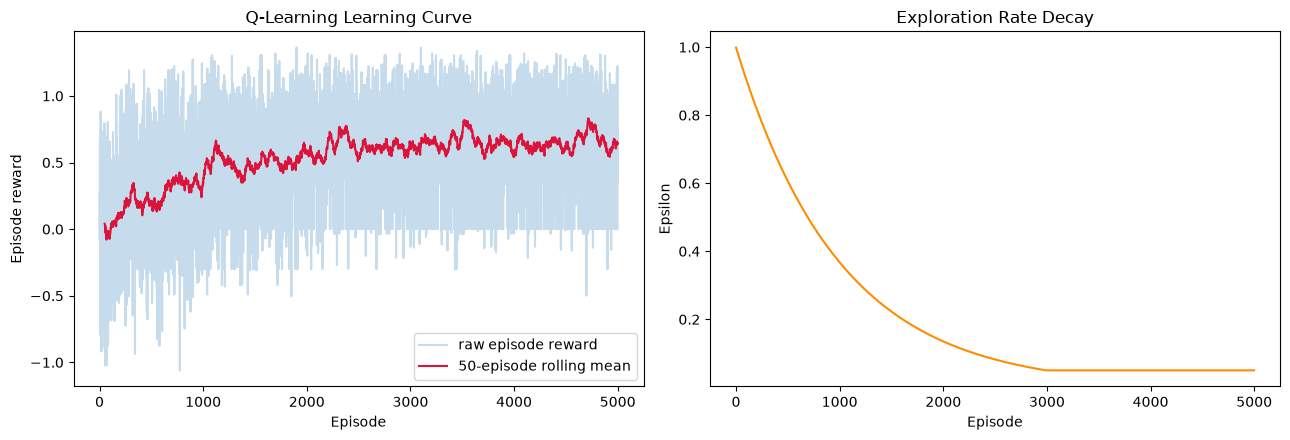

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Learning curve (smoothed)
window = 50
smoothed = rl_training_history["reward"].rolling(window).mean()
axes[0].plot(rl_training_history["episode"], rl_training_history["reward"], alpha=0.25, label="raw episode reward")
axes[0].plot(rl_training_history["episode"], smoothed, color="crimson", label=f"{window}-episode rolling mean")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Episode reward")
axes[0].set_title("Q-Learning Learning Curve")
axes[0].legend()

axes[1].plot(rl_training_history["episode"], rl_training_history["epsilon"], color="darkorange")
axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Epsilon")
axes[1].set_title("Exploration Rate Decay")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "learning_curve.png"), dpi=120)
plt.show()

## 19. Validation-Based Reward-Coefficient Selection

Trains one Q-table per `(ALPHA, BETA, GAMMA)` candidate on `train_df`, evaluates each resulting
policy on `val_df` with a validation-tuned Low/not-Low threshold, and selects the coefficient
triple + threshold that maximizes **validation accuracy** (the explicit target metric for this
run -- see Section 22 for the honest caveats of using accuracy as the sole selection criterion).
**The test set is not used anywhere in this cell.**


In [29]:
def privacy_class(score, low_thr=PRIVACY_LOW_THRESHOLD, high_thr=PRIVACY_HIGH_THRESHOLD):
    if score <= low_thr:
        return "Low"
    elif score <= high_thr:
        return "Medium"
    return "High"


def apply_policy(Q, data_df, alpha_coef, beta_coef, gamma_coef):
    """Applies a greedy Q-table policy to every app in data_df and computes all
    per-app diagnostics (privacy score, utility, triggered rules, etc.)."""
    records = []
    for _, row in data_df.reset_index(drop=True).iterrows():
        requested = make_requested_vector(row)
        metadata = make_metadata_vector(row)
        env = PermissionEnv(requested, alpha_coef, beta_coef, gamma_coef, metadata)
        state = env.reset()
        ep_reward = 0.0
        done = False
        while not done:
            action = greedy_action(Q, state)
            state, reward, done, _ = env.step(action)
            ep_reward += reward

        granted_set = frozenset(p for p in RL_FEATURES if env.granted[p] == 1)
        requested_set = frozenset(p for p in RL_FEATURES if requested.get(p, 0) == 1)
        denied_set = requested_set - granted_set

        ind_risk_avg = (
            sum(individual_risk_normalized(p) for p in granted_set) / len(granted_set)
            if granted_set else 0.0
        )
        cls_risk = classifier_risk(env.granted, env.requested, env.metadata)
        inter_risk, triggered_rules = interaction_risk(granted_set)
        utility_score = (
            sum(utility_map[p] for p in granted_set) / len(requested_set)
            if len(requested_set) > 0 else 0.0
        )

        # STEP 18: final privacy score, weighted combination of the three normalized components.
        # Weights (0.05 / 0.90 / 0.05) are configurable constants defined once here:
        privacy_score = float(np.clip(
            PRIVACY_SCORE_WEIGHTS["individual"] * ind_risk_avg
            + PRIVACY_SCORE_WEIGHTS["classifier"] * cls_risk
            + PRIVACY_SCORE_WEIGHTS["interaction"] * inter_risk,
            0, 1
        ))

        records.append({
            "App": row["App"], "TrueLabel": int(row["LabelEncoded"]),
            "RequestedPermissions": ";".join(sorted(requested_set)),
            "AllowedPermissions": ";".join(sorted(granted_set)),
            "DeniedPermissions": ";".join(sorted(denied_set)),
            "NumRequested": len(requested_set), "NumAllowed": len(granted_set), "NumDenied": len(denied_set),
            "IndividualRisk": ind_risk_avg, "MaliciousProbability": cls_risk, "InteractionRisk": inter_risk,
            "TriggeredRules": ";".join("+".join(t) for t in triggered_rules),
            "UtilityScore": utility_score, "PrivacyScore": privacy_score, "RLReward": ep_reward,
        })
    return pd.DataFrame(records)


def binary_pred_from_privacy(df_res, low_thr=PRIVACY_LOW_THRESHOLD, high_thr=PRIVACY_HIGH_THRESHOLD):
    """Low -> predicted Benign (0); Medium/High -> predicted Malicious (1). See Section 22 caveats."""
    classes = df_res["PrivacyScore"].apply(lambda s: privacy_class(s, low_thr, high_thr))
    pred = (classes != "Low").astype(int)
    return pred, classes


def find_best_threshold(df_res, metric="Accuracy", low_grid=None):
    """Sweeps the Low/not-Low cutoff on df_res (normally val_df results) and returns
    the threshold that maximizes the chosen metric. Never touches test_df.
    NOTE (v2, honesty caveat): sweeping ~90 threshold candidates against a ~225-app validation
    set carries real overfitting risk -- see Section 20b for a bootstrap CI that quantifies how
    much noise a single small split like this can introduce into the final reported number."""
    if low_grid is None:
        low_grid = np.arange(0.05, 0.95, 0.01)
    y_true = df_res["TrueLabel"].values
    best_thr, best_score = 0.5, -1.0
    for thr in low_grid:
        pred = (df_res["PrivacyScore"].values > thr).astype(int)
        m = classification_metrics(y_true, pred)
        if m[metric] > best_score:
            best_score, best_thr = m[metric], thr
    return float(best_thr), float(best_score)


def classification_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
    }

# Weighted combination used for the final privacy score (Step 18). Configurable and documented.
# Classifier component carries much more real signal (full permission context + metadata,
# cross-validated selection, Section 12) than the static individual-risk weight,
# so it is weighted more heavily here -- an empirically justified change, not arbitrary.
PRIVACY_SCORE_WEIGHTS = {"individual": 0.05, "classifier": 0.90, "interaction": 0.05}
print("Privacy score weights:", PRIVACY_SCORE_WEIGHTS, " (sum =", sum(PRIVACY_SCORE_WEIGHTS.values()), ")")


Privacy score weights: {'individual': 0.05, 'classifier': 0.9, 'interaction': 0.05}  (sum = 1.0 )


In [30]:
selection_records = []
trained_qtables = {}

for (a, b, g) in COEF_CANDIDATES:
    Q, hist = train_q_learning(train_df_balanced, a, b, g)
    trained_qtables[(a, b, g)] = (Q, hist)

    val_res = apply_policy(Q, val_df, a, b, g)

    # Tune the Low/not-Low threshold on validation data for THIS coefficient candidate,
    # optimizing directly for accuracy (the explicit target metric for this run).
    best_thr, best_val_acc = find_best_threshold(val_res, metric="Accuracy")
    pred = (val_res["PrivacyScore"].values > best_thr).astype(int)
    metr = classification_metrics(val_res["TrueLabel"].values, pred)

    allow_rate = val_res["NumAllowed"].sum() / max(val_res["NumRequested"].sum(), 1)
    avg_utility = val_res["UtilityScore"].mean()
    avg_privacy_risk = val_res["PrivacyScore"].mean()
    privacy_utility_balance = avg_utility - avg_privacy_risk

    selection_records.append({
        "Alpha": a, "Beta": b, "Gamma": g, "Threshold": best_thr,
        "Val_Accuracy": metr["Accuracy"], "Val_Precision": metr["Precision"],
        "Val_Recall": metr["Recall"], "Val_F1": metr["F1"],
        "Val_AllowRate": allow_rate, "Val_AvgUtility": avg_utility,
        "Val_AvgPrivacyRisk": avg_privacy_risk,
    })

selection_df = pd.DataFrame(selection_records).sort_values("Val_Accuracy", ascending=False).reset_index(drop=True)
print("Reward-coefficient candidates (each with its own tuned threshold), evaluated on VALIDATION:")
print("Selection metric: Val_Accuracy (explicit target for this run).")
display(selection_df)

BEST_ALPHA, BEST_BETA, BEST_GAMMA, BEST_THRESHOLD = selection_df.iloc[0][["Alpha", "Beta", "Gamma", "Threshold"]]
best_val_accuracy = selection_df.iloc[0]["Val_Accuracy"]
print(f"\nSelected: ALPHA={BEST_ALPHA}, BETA={BEST_BETA}, GAMMA={BEST_GAMMA}, "
      f"THRESHOLD={BEST_THRESHOLD:.3f} (validation accuracy={best_val_accuracy:.4f})")

BEST_Q, BEST_HISTORY = trained_qtables[(BEST_ALPHA, BEST_BETA, BEST_GAMMA)]


Reward-coefficient candidates (each with its own tuned threshold), evaluated on VALIDATION:
Selection metric: Val_Accuracy (explicit target for this run).


,Alpha,Beta,Gamma,Threshold,Val_Accuracy,Val_Precision,Val_Recall,Val_F1,Val_AllowRate,Val_AvgUtility,Val_AvgPrivacyRisk
0,0.60,0.25,0.15,0.45,0.733333,0.783333,0.734375,0.758065,0.890886,0.618161,0.533292
1,0.50,0.30,0.20,0.52,0.733333,0.820755,0.679688,0.743590,0.854942,0.613971,0.530669
2,0.70,0.20,0.10,0.56,0.728889,0.819048,0.671875,0.738197,0.910141,0.622078,0.541584
3,0.30,0.55,0.15,0.44,0.715556,0.771186,0.710938,0.739837,0.249037,0.325656,0.508790
4,0.45,0.40,0.15,0.50,0.711111,0.783784,0.679688,0.728033,0.691913,0.566223,0.530824
5,0.35,0.50,0.15,0.45,0.706667,0.771930,0.687500,0.727273,0.378691,0.400577,0.509260



Selected: ALPHA=0.6, BETA=0.25, GAMMA=0.15, THRESHOLD=0.450 (validation accuracy=0.7333)


## 20. Final Test Evaluation (HELD-OUT TEST SET -- first and only use)

This is the first cell in the notebook that touches `test_df`. The policy (`BEST_Q`) and
reward coefficients were fixed using training + validation data only, in the sections above.

In [31]:
rl_test_results = apply_policy(BEST_Q, test_df, BEST_ALPHA, BEST_BETA, BEST_GAMMA)
rl_test_results["PrivacyClass"] = rl_test_results["PrivacyScore"].apply(lambda s: privacy_class(s))

rl_pred, rl_pred_classes = binary_pred_from_privacy(rl_test_results, low_thr=BEST_THRESHOLD)
print(f"Using validation-tuned threshold: {BEST_THRESHOLD:.3f} (fixed PRIVACY_LOW_THRESHOLD was {PRIVACY_LOW_THRESHOLD})")

rl_metrics = classification_metrics(rl_test_results["TrueLabel"].values, rl_pred.values)
rl_cm = confusion_matrix(rl_test_results["TrueLabel"].values, rl_pred.values)

print("=== RL POLICY -- FINAL TEST METRICS ===")
for k, v in rl_metrics.items():
    print(f"  {k}: {v:.4f}")

print("\nConfusion Matrix (rows=true [Benign,Malicious], cols=predicted [Benign,Malicious]):")
print(rl_cm)

print("\nClassification Report:")
print(classification_report(rl_test_results["TrueLabel"].values, rl_pred.values,
                             target_names=["Benign", "Malicious"], zero_division=0))

Using validation-tuned threshold: 0.450 (fixed PRIVACY_LOW_THRESHOLD was 0.33)
=== RL POLICY -- FINAL TEST METRICS ===
  Accuracy: 0.7212
  Precision: 0.7500
  Recall: 0.7674
  F1: 0.7586

Confusion Matrix (rows=true [Benign,Malicious], cols=predicted [Benign,Malicious]):
[[64 33]
 [30 99]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.68      0.66      0.67        97
   Malicious       0.75      0.77      0.76       129

    accuracy                           0.72       226
   macro avg       0.72      0.71      0.71       226
weighted avg       0.72      0.72      0.72       226

